# Rainfall erosivity layer
This notebook is to guide the creation of the R layer. First, as the 10km UHTH resolution, and then, to modify it depending on first, precipitation RCP scenarios, and second, precipitation hazard risk scenarions.

# R baseline creation (GloReda)
This is base on GloREDa, which is a publication that esimates monthly R. So obvious thing, is to first explore this data

## GlodRED exploration

In [1]:
import sbtn_leaf.map_plotting as mp
import sbtn_leaf.map_calculations as mc

from contextlib import ExitStack
from pathlib import Path
import numpy as np
import rasterio

Could not determine dtype for column 1, falling back to string


In [2]:
# data
R_jan_fp = '../../data/soil_erosion/GloREDa/Rfactor_January.tif'
R_aug_fp = '../../data/soil_erosion/GloREDa/Rfactor_August.tif'
r_og_fp = "../../data/soil_erosion/GloSEM_v1.1/RUSLE_RFactor_v1.1_25km.tif"

In [3]:
R_quant = [0, 1, 20, 50, 100, 200, 400, 700, 1000, 1400, 2000]

Plotting

In [8]:
mp.inspect_raster(R_jan_fp)

File: ../../data/soil_erosion/GloREDa/Rfactor_January.tif
Driver: GTiff
Width, Height: 43200, 17924
Number of Bands: 1
CRS: EPSG:4326
Bounds: BoundingBox(left=-180.0, bottom=-61.996666666666584, right=179.99999999999983, top=87.37)
Pixel Size: (0.00833333333333333, 0.00833333333333333)
No-data Value: -32768.0

--- Raster Metadata ---
AREA_OR_POINT: Area

--- Band Information ---

Band 1:
  Data Type: int16
  Min Value: 0
  Max Value: 6864
  Mean Value: 166.79739116610466
  Standard Deviation: 348.8831629329275


Raster has 5,763 unique values. Min: 0.00. Max: 6,864.00
Using quantile edges


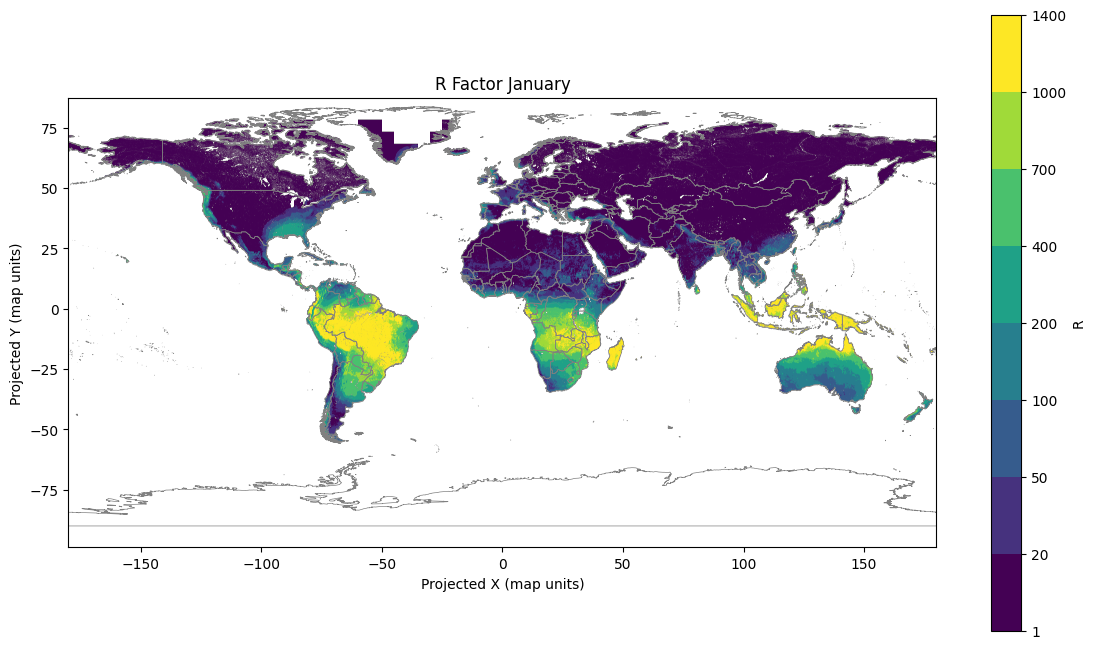

In [10]:
mp.plot_raster_on_world_extremes_cutoff(R_jan_fp, 'R Factor January', 'R', perc_cutoff=0, quantiles=R_quant)

Looks ok, just like in the paper.

So now, just adding all of them, can find the actual annual R.

In [4]:
# Filepaths
R_feb_fp = '../../data/soil_erosion/GloREDa/Rfactor_February.tif'
R_mar_fp = '../../data/soil_erosion/GloREDa/Rfactor_March.tif'
R_apr_fp = '../../data/soil_erosion/GloREDa/Rfactor_April.tif'
R_may_fp = '../../data/soil_erosion/GloREDa/Rfactor_May.tif'
R_jun_fp = '../../data/soil_erosion/GloREDa/Rfactor_June.tif'
R_jul_fp = '../../data/soil_erosion/GloREDa/Rfactor_July.tif'
R_sep_fp = '../../data/soil_erosion/GloREDa/Rfactor_September.tif'
R_oct_fp = '../../data/soil_erosion/GloREDa/Rfactor_October.tif'
R_nov_fp = '../../data/soil_erosion/GloREDa/Rfactor_November.tif'
R_dec_fp = '../../data/soil_erosion/GloREDa/Rfactor_December.tif'

In [5]:
R_factor_files = [
    R_jan_fp,
    R_feb_fp,
    R_mar_fp,
    R_apr_fp,
    R_may_fp,
    R_jun_fp,
    R_jul_fp,
    R_aug_fp,
    R_sep_fp,
    R_oct_fp,
    R_nov_fp,
    R_dec_fp,
]

Simply adding...

In [6]:
def sum_rasters(filepaths, output_fp, nodata = -9999.0, output_dtype = np.float32):
    """Sum single-band rasters that share the same geospatial grid.

    Nodata in one raster is skipped (treated as 0) as long as at least one
    raster has a valid value at that pixel. A pixel is nodata in the output
    only when it is nodata in every input.

    The sum is accumulated in float64 and only cast to output_dtype at the end,
    so a small integer dtype (e.g. int16) cannot silently overflow and wrap.
    """
    filepaths = [Path(fp) for fp in filepaths]
    output_fp = Path(output_fp)
    output_dtype = np.dtype(output_dtype)

    if not filepaths:
        raise ValueError("At least one input raster is required.")

    if output_fp.resolve() in {fp.resolve() for fp in filepaths}:
        raise ValueError("The output path must not be one of the input paths.")

    with ExitStack() as stack:
        datasets = []
        for fp in filepaths:
            if not fp.is_file():
                raise FileNotFoundError(f"Input raster not found: {fp}")
            datasets.append(stack.enter_context(rasterio.open(fp)))

        reference = datasets[0]
        if reference.crs is None:
            raise ValueError(f"Input raster has no CRS: {filepaths[0]}")
        if reference.count != 1:
            raise ValueError(f"Expected single-band raster: {filepaths[0]}")

        for fp, src in zip(filepaths[1:], datasets[1:]):
            if src.crs is None:
                raise ValueError(f"Input raster has no CRS: {fp}")
            if src.crs != reference.crs:
                raise ValueError(f"CRS mismatch: {fp}")
            if (src.width, src.height) != (reference.width, reference.height):
                raise ValueError(f"Raster dimensions mismatch: {fp}")
            if src.transform != reference.transform:
                raise ValueError(f"Pixel grid/transform mismatch: {fp}")
            if src.count != 1:
                raise ValueError(f"Expected single-band raster: {fp}")

        total = np.zeros((reference.height, reference.width), dtype=np.float64)
        valid = np.zeros(total.shape, dtype=bool)

        for src in datasets:
            band = src.read(1, masked=True)
            values = np.asarray(band.data, dtype=np.float64)
            band_valid = ~np.ma.getmaskarray(band) & np.isfinite(values)
            valid |= band_valid
            total += np.where(band_valid, values, 0)

        # Make sure the sums (and nodata) fit in the requested output dtype
        if np.issubdtype(output_dtype, np.integer):
            info = np.iinfo(output_dtype)
            if valid.any():
                lo, hi = total[valid].min(), total[valid].max()
                if lo < info.min or hi > info.max:
                    raise ValueError(
                        f"Summed values [{lo}, {hi}] do not fit in {output_dtype} "
                        f"[{info.min}, {info.max}]; use a larger dtype (e.g. int32 or float32)."
                    )
            if not info.min <= nodata <= info.max:
                raise ValueError(f"nodata {nodata} does not fit in {output_dtype}.")
            if (valid & (total == nodata)).any():
                raise ValueError(f"Some valid sums equal nodata ({nodata}); choose another nodata value.")

        result = total.astype(output_dtype)
        del total
        result[~valid] = nodata

        profile = reference.profile.copy()
        profile.update(
            count=1,
            dtype=output_dtype.name,
            nodata=nodata,
            compress="deflate",
        )

    output_fp.parent.mkdir(parents=True, exist_ok=True)
    with rasterio.open(output_fp, "w", **profile) as dst:
        dst.write(result, 1)

    return output_fp


Summing...

In [7]:
annual_R_fp = sum_rasters(
    R_factor_files,
    "../../RUSLE/notebooks/Rfactor_Annual.tif",
    output_dtype=np.int32,  # annual R reaches ~50,500, above the int16 max of 32,767
    nodata=-32768.0
)

Checking...

In [8]:
mp.inspect_raster(annual_R_fp)

File: ..\..\RUSLE\notebooks\Rfactor_Annual.tif
Driver: GTiff
Width, Height: 43200, 17924
Number of Bands: 1
CRS: EPSG:4326
Bounds: BoundingBox(left=-180.0, bottom=-61.996666666666584, right=179.99999999999983, top=87.37)
Pixel Size: (0.00833333333333333, 0.00833333333333333)
No-data Value: -32768.0

--- Raster Metadata ---
AREA_OR_POINT: Area

--- Band Information ---

Band 1:
  Data Type: int32
  Min Value: 0
  Max Value: 50537
  Mean Value: 2084.4374401791765
  Standard Deviation: 3163.562737563338


Raster has 39,096 unique values. Min: 0.00. Max: 50,537.00
Using quantiles
All positives route (quantiles)


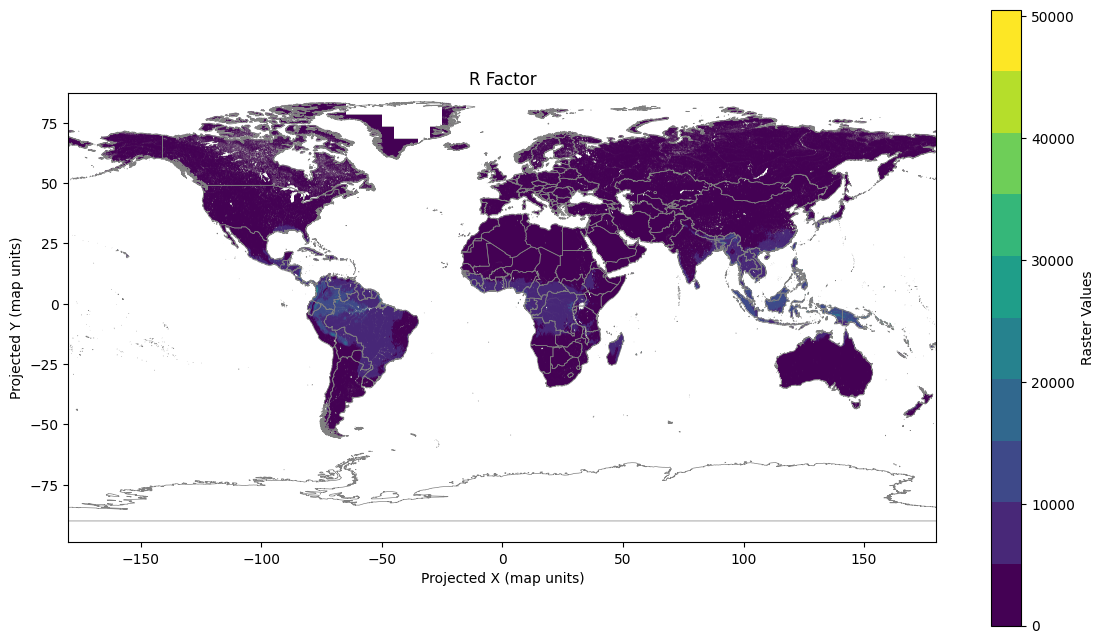

In [9]:
mp.plot_raster_on_world_extremes_cutoff(annual_R_fp, "R Factor", perc_cutoff=0, quantiles=10)

In [10]:
mp.inspect_raster(r_og_fp)

File: ../../data/soil_erosion/GloSEM_v1.1/RUSLE_RFactor_v1.1_25km.tif
Driver: GTiff
Width, Height: 1728, 673
Number of Bands: 1
CRS: EPSG:4326
Bounds: BoundingBox(left=-180.0, bottom=-56.6229166666667, right=179.99999999999943, top=83.58541666666642)
Pixel Size: (0.208333333333333, 0.208333333333333)
No-data Value: -1.7976931348623157e+308

--- Raster Metadata ---
TIFFTAG_SOFTWARE: GDAL 3.8.1e (3080114) (4.6.0;1710;3.0.1;2.1.6;;0x10302;5.4.5;), PROJ 9.3.1 (EPSG.VERSION=v10.098;EPSG.DATE=2023-11-24;ESRI.VERSION=ArcGIS Pro 3.2;ESRI.DATE=2023-11-02;PROJ_DATA.VERSION=1.16;)
AREA_OR_POINT: Area

--- Band Information ---

Band 1:
  Data Type: float64
  Min Value: 0.0
  Max Value: 26179.59138172449
  Mean Value: 2335.9360160304327
  Standard Deviation: 3023.1130814654384
  Band Metadata:
    STATISTICS_MAXIMUM: 26179.591381724
    STATISTICS_MEAN: 2335.9360160304
    STATISTICS_MINIMUM: 0
    STATISTICS_SKIPFACTORX: 1
    STATISTICS_SKIPFACTORY: 1
    STATISTICS_STDDEV: 3023.1184910824


## Comparison with GloSEM v1.1 R factor
`annual_R_fp` (sum of the 12 GloREDa monthly rasters, 1 km) vs `r_og_fp` (annual R shipped with GloSEM v1.1, 25 km).

The two grids differ in resolution and are not aligned, so the 1 km annual R is first area-averaged onto the GloSEM 25 km grid. All comparisons below are made on that common grid.

In [11]:
from rasterio.warp import reproject, Resampling
import pandas as pd
import matplotlib.pyplot as plt

annual_R_25km_fp = Path("../../RUSLE/notebooks/Rfactor_Annual_25km.tif")
# GloSEM nodata is -1.8e308 (float64 min), which overflows float32 in the plotting helpers,
# so we also write a float32 copy with nodata -9999 to plot from
r_og_clean_fp = Path("../../RUSLE/notebooks/Rfactor_GloSEM_v1.1_25km_f32.tif")

with rasterio.open(r_og_fp) as og:
    og_profile = og.profile.copy()
    og_shape, og_transform, og_crs = (og.height, og.width), og.transform, og.crs
    r_og = og.read(1, masked=True).astype(np.float64)
r_og = np.ma.masked_invalid(r_og)

# Area-average the 1 km annual R onto the 25 km GloSEM grid (nodata pixels are ignored)
r_new = np.full(og_shape, np.nan, dtype=np.float64)
with rasterio.open(annual_R_fp) as src:
    reproject(
        source=rasterio.band(src, 1),
        destination=r_new,
        src_nodata=src.nodata,
        dst_transform=og_transform,
        dst_crs=og_crs,
        dst_nodata=np.nan,
        resampling=Resampling.average,
    )
r_new = np.ma.masked_invalid(r_new)

og_profile.update(dtype="float32", nodata=-9999.0, compress="deflate")
for fp, arr in [(annual_R_25km_fp, r_new), (r_og_clean_fp, r_og)]:
    with rasterio.open(fp, "w", **og_profile) as dst:
        dst.write(arr.filled(-9999.0).astype(np.float32), 1)

### Summary statistics
Stats on each raster's own valid pixels, and on the pixels valid in both (the fair comparison). Agreement metrics use the common pixels only.

In [12]:
def _describe(values):
    return {
        "n pixels": values.size,
        "mean": values.mean(),
        "std": values.std(),
        "min": values.min(),
        "p05": np.percentile(values, 5),
        "median": np.median(values),
        "p95": np.percentile(values, 95),
        "max": values.max(),
    }

common = ~np.ma.getmaskarray(r_new) & ~np.ma.getmaskarray(r_og)
new_c, og_c = r_new.data[common], r_og.data[common]

stats = pd.DataFrame({
    "GloREDa sum (own valid px)": _describe(r_new.compressed()),
    "GloSEM v1.1 (own valid px)": _describe(r_og.compressed()),
    "GloREDa sum (common px)": _describe(new_c),
    "GloSEM v1.1 (common px)": _describe(og_c),
}).T
display(stats.round(1))

diff_c = new_c - og_c
nonzero = og_c > 0
agreement = pd.Series({
    "pixels only in GloREDa sum": int((~np.ma.getmaskarray(r_new) & np.ma.getmaskarray(r_og)).sum()),
    "pixels only in GloSEM v1.1": int((np.ma.getmaskarray(r_new) & ~np.ma.getmaskarray(r_og)).sum()),
    "mean bias (new - GloSEM)": diff_c.mean(),
    "median bias (new - GloSEM)": np.median(diff_c),
    "relative bias of means (%)": 100 * (new_c.mean() / og_c.mean() - 1),
    "median ratio new / GloSEM": np.median(new_c[nonzero] / og_c[nonzero]),
    "MAE": np.abs(diff_c).mean(),
    "RMSE": np.sqrt((diff_c ** 2).mean()),
    "Pearson r": np.corrcoef(new_c, og_c)[0, 1],
    "Spearman rho": pd.Series(new_c).corr(pd.Series(og_c), method="spearman"),
})
display(agreement.round(3).to_frame("value"))

,n pixels,mean,std,min,p05,median,p95,max
GloREDa sum (own valid px),366149.0,2171.5,3389.4,0.0,36.0,475.6,9439.3,39518.5
GloSEM v1.1 (own valid px),279421.0,2335.9,3023.1,0.0,133.4,685.8,8934.0,26179.6
GloREDa sum (common px),279410.0,2402.9,3283.3,0.0,74.0,661.7,9447.5,38785.5
GloSEM v1.1 (common px),279410.0,2335.8,3022.8,0.0,133.4,685.8,8933.6,26179.6


,value
pixels only in GloREDa sum,86739.000
pixels only in GloSEM v1.1,11.000
mean bias (new - GloSEM),67.161
median bias (new - GloSEM),-4.610
relative bias of means (%),2.875
median ratio new / GloSEM,0.991
MAE,646.939
RMSE,1415.888
Pearson r,0.903
Spearman rho,0.867


### Side-by-side maps (same colour classes)

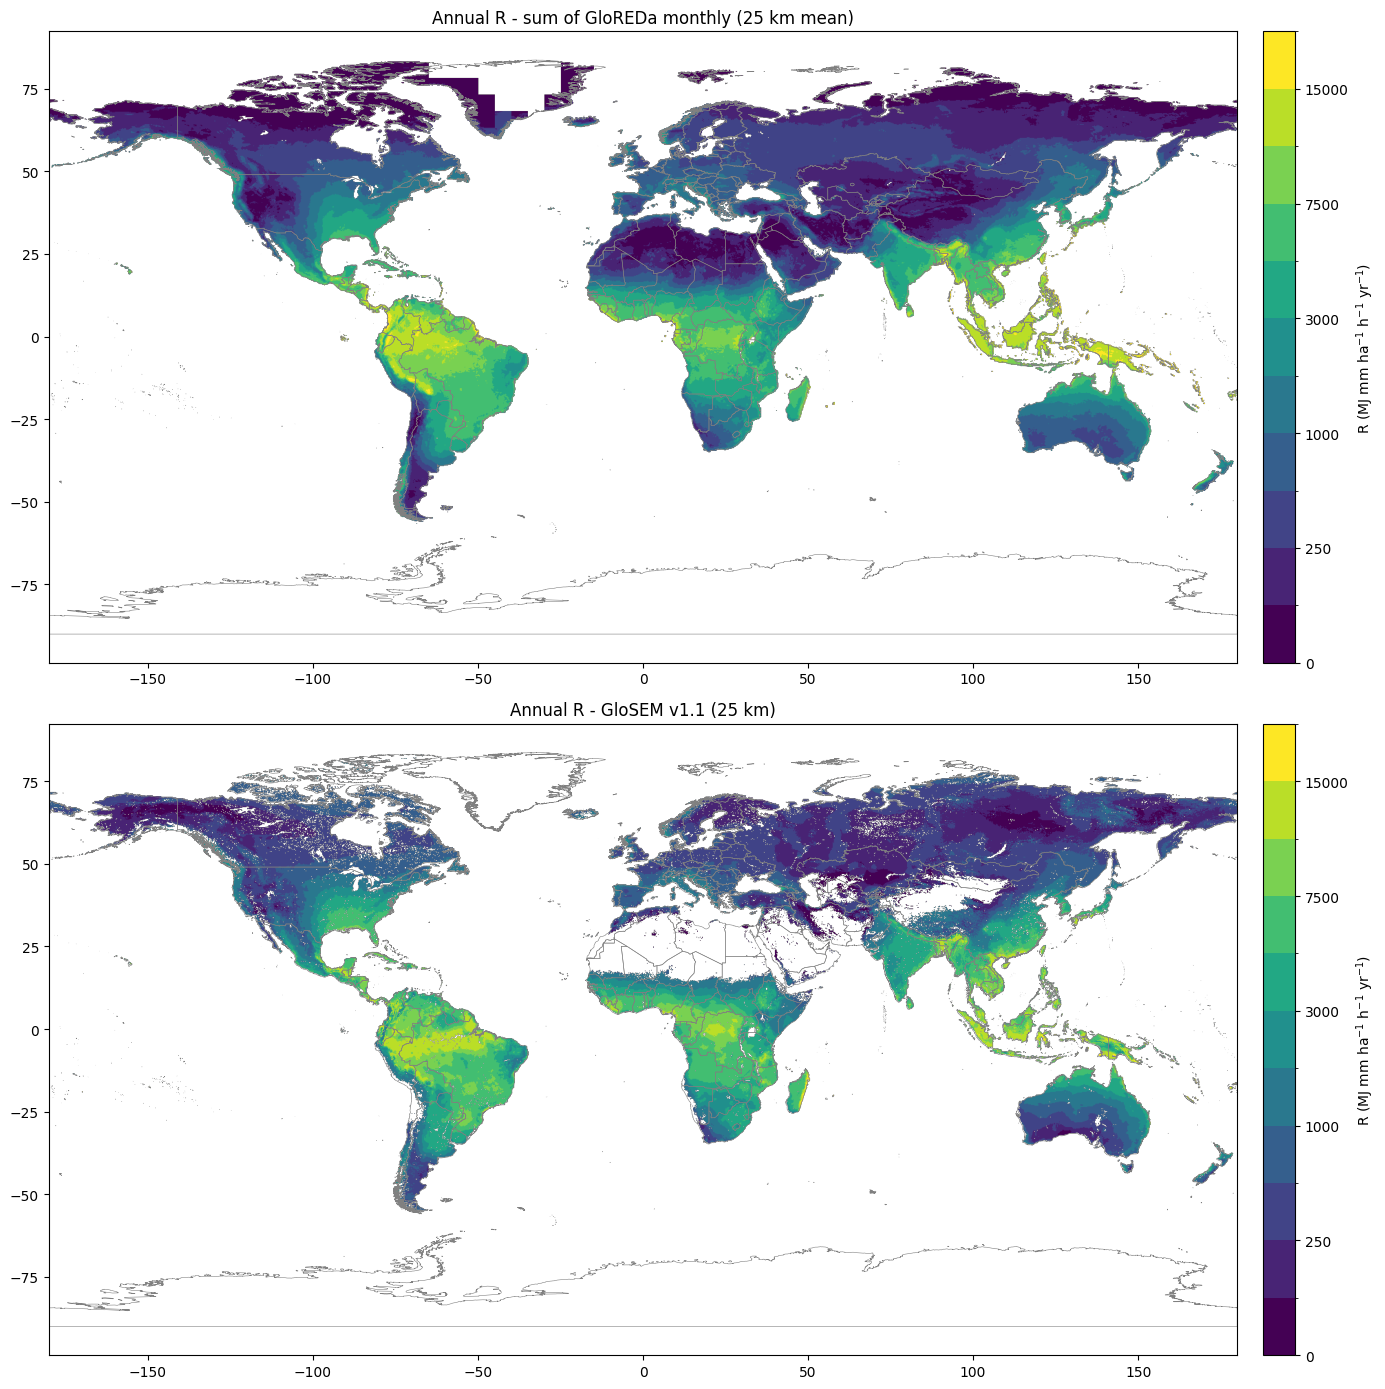

(<Figure size 1400x1400 with 4 Axes>,
 array([[<Axes: title={'center': 'Annual R - sum of GloREDa monthly (25 km mean)'}>],
        [<Axes: title={'center': 'Annual R - GloSEM v1.1 (25 km)'}>]],
       dtype=object))

In [13]:
R_annual_quant = [0, 100, 250, 500, 1000, 2000, 3000, 5000, 7500, 10000, 15000, 55000]

mp.plot_n_rasters_on_world_extremes_cutoff(
    [annual_R_25km_fp, r_og_clean_fp],
    titles=["Annual R - sum of GloREDa monthly (25 km mean)", "Annual R - GloSEM v1.1 (25 km)"],
    label_title="R (MJ mm ha$^{-1}$ h$^{-1}$ yr$^{-1}$)",
    perc_cutoff=0,
    quantiles=R_annual_quant,
    n_cols=1,
    x_size=14,
    y_size=7,
)

### Difference maps
Absolute (GloREDa sum − GloSEM) and relative (% of GloSEM) differences. Red = our annual R is higher than GloSEM. Colour scales are clipped at the 1st/99th percentiles.

Raster has 273,511 unique values. Min: -2,728.40. Max: 5,865.68
Not using quantiles
2-sided route (continuous)


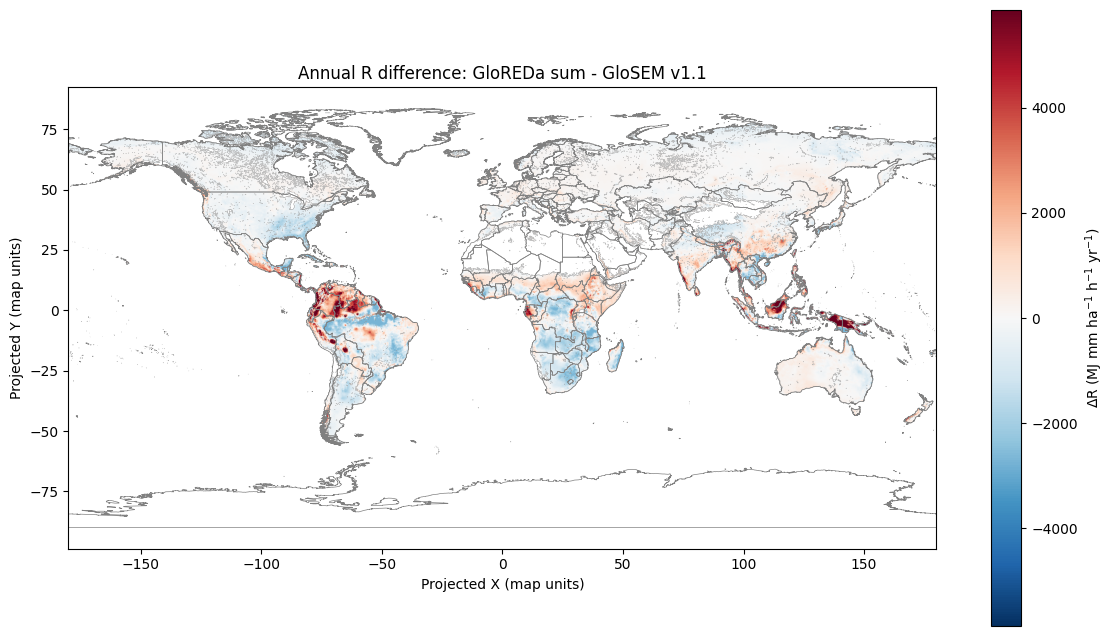

Raster has 272,507 unique values. Min: -94.72. Max: 266.34
Not using quantiles
2-sided route (continuous)


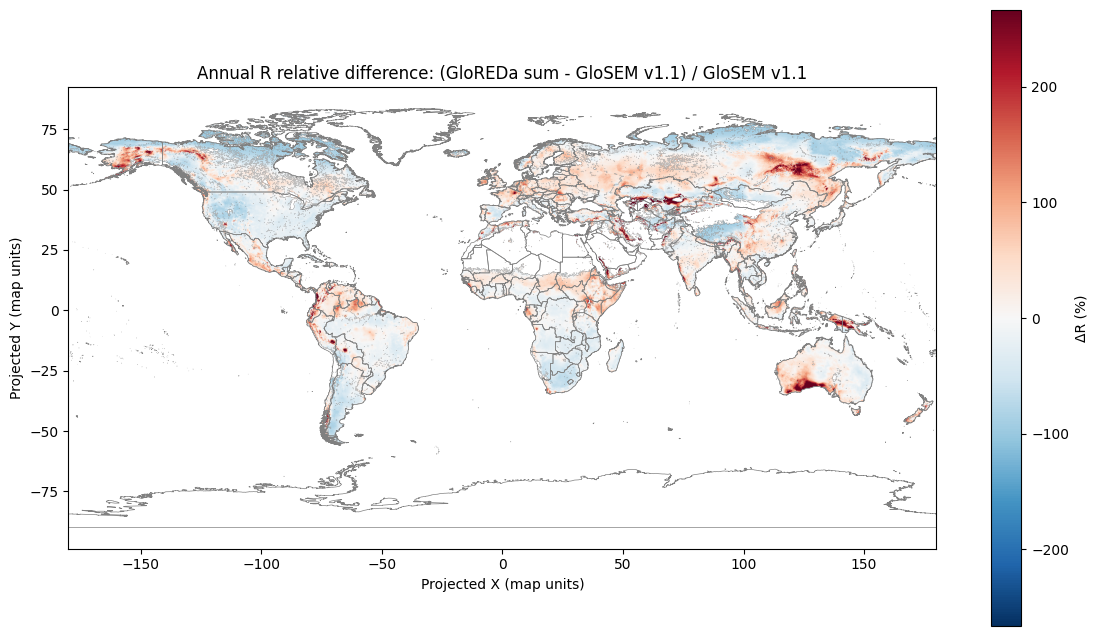

In [14]:
diff_fp = Path("../../RUSLE/notebooks/Rfactor_diff_vs_GloSEM_25km.tif")
pct_diff_fp = Path("../../RUSLE/notebooks/Rfactor_pctdiff_vs_GloSEM_25km.tif")

new_f, og_f = r_new.filled(np.nan), r_og.filled(np.nan)
diff = new_f - og_f
pct_diff = 100 * diff / np.where(og_f > 0, og_f, np.nan)
for fp, arr in [(diff_fp, diff), (pct_diff_fp, pct_diff)]:
    with rasterio.open(fp, "w", **og_profile) as dst:
        dst.write(np.where(np.isfinite(arr), arr, -9999.0).astype(np.float32), 1)

mp.plot_raster_on_world_extremes_cutoff(
    diff_fp, "Annual R difference: GloREDa sum - GloSEM v1.1",
    label_title="ΔR (MJ mm ha$^{-1}$ h$^{-1}$ yr$^{-1}$)", perc_cutoff=1, diverg0=True, cmap="RdBu_r",
)
mp.plot_raster_on_world_extremes_cutoff(
    pct_diff_fp, "Annual R relative difference: (GloREDa sum - GloSEM v1.1) / GloSEM v1.1",
    label_title="ΔR (%)", perc_cutoff=1, diverg0=True, cmap="RdBu_r",
)

### Pixel-by-pixel scatter and distributions

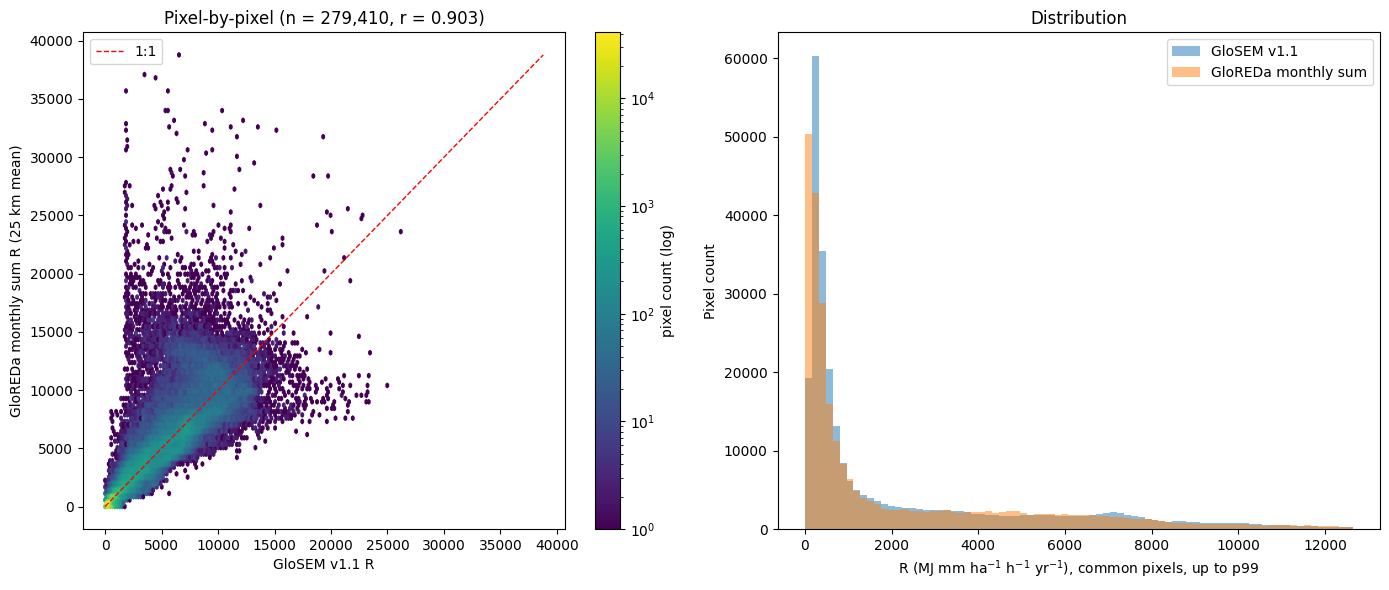

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

hb = axes[0].hexbin(og_c, new_c, gridsize=120, bins="log", mincnt=1, cmap="viridis")
lim = max(og_c.max(), new_c.max())
axes[0].plot([0, lim], [0, lim], "r--", lw=1, label="1:1")
axes[0].set_xlabel("GloSEM v1.1 R")
axes[0].set_ylabel("GloREDa monthly sum R (25 km mean)")
axes[0].set_title(f"Pixel-by-pixel (n = {common.sum():,}, r = {agreement['Pearson r']:.3f})")
axes[0].legend()
fig.colorbar(hb, ax=axes[0], label="pixel count (log)")

bins = np.linspace(0, np.percentile(np.concatenate([new_c, og_c]), 99), 80)
axes[1].hist(og_c, bins=bins, alpha=0.5, label="GloSEM v1.1")
axes[1].hist(new_c, bins=bins, alpha=0.5, label="GloREDa monthly sum")
axes[1].set_xlabel("R (MJ mm ha$^{-1}$ h$^{-1}$ yr$^{-1}$), common pixels, up to p99")
axes[1].set_ylabel("Pixel count")
axes[1].set_title("Distribution")
axes[1].legend()

plt.tight_layout()
plt.show()